# ARTI 502 — Deep Learning: 1st Assignment
## Training-Testing Neural Net with MNIST Dataset using PyTorch
**Imam Abdulrahman Bin Faisal University — College of Computer Science & IT — Year 2026, Term 1**

| # | Member Name | Academic ID |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |
| 4 | | |
| 5 | | |

## Task 1: Install PyTorch
Install PyTorch (and torchvision for the MNIST dataset), then import it into the code.
This notebook is saved as **`Assigment-1 DL`**.

In [1]:
%pip install torch torchvision matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import matplotlib.pyplot as plt
import time

import random
import pandas as pd

print("PyTorch version     :", torch.__version__)
print("Torchvision version :", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device              :", device)

torch.manual_seed(42)   # reproducible results


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)


PyTorch version     : 2.14.1+cpu
Torchvision version : 0.29.1+cpu
Device              : cpu


## Task 2: Download and Load the Dataset
MNIST: 28×28 grayscale handwritten digits 0–9. torchvision downloads it directly from code.

*Note:* torchvision's MNIST training file has 60,000 images. To match the assignment's
**50,000 training / 10,000 test** description, we split the 60,000 into 50,000 for training
and 10,000 for validation, and keep the official 10,000 test images for testing.

In [22]:
# Transform: convert image to tensor [0,1] and normalize with MNIST mean/std
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download directly from Python code
full_train = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# 50,000 train / 10,000 validation split
train_set, val_set = random_split(full_train, [50000, 10000],
                                  generator=torch.Generator().manual_seed(42))

BATCH_SIZE = 32
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=1000, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=1000, shuffle=False)

print("Dataset loaded successfully!")
print(f"Training images   : {len(train_set)}")
print(f"Validation images : {len(val_set)}")
print(f"Test images       : {len(test_set)}")
print("Classes:", full_train.classes)

Dataset loaded successfully!
Training images   : 50000
Validation images : 10000
Test images       : 10000
Classes: ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


## Task 3: Inspect the Dataset
### 3.1 Images tensor size

In [23]:
# Take one mini-batch from the dataloader
images, labels = next(iter(train_loader))

print("Images tensor size :", images.size())    # [N, C, H, W] = [32, 1, 28, 28]
print("Labels tensor size :", labels.size())    # [32]
print("Data type          :", images.dtype)
print("First 10 labels    :", labels[:10].tolist())

Images tensor size : torch.Size([32, 1, 28, 28])
Labels tensor size : torch.Size([32])
Data type          : torch.float32
First 10 labels    : [5, 2, 7, 3, 2, 2, 4, 3, 2, 6]


### 3.2 Data images visualization using matplotlib

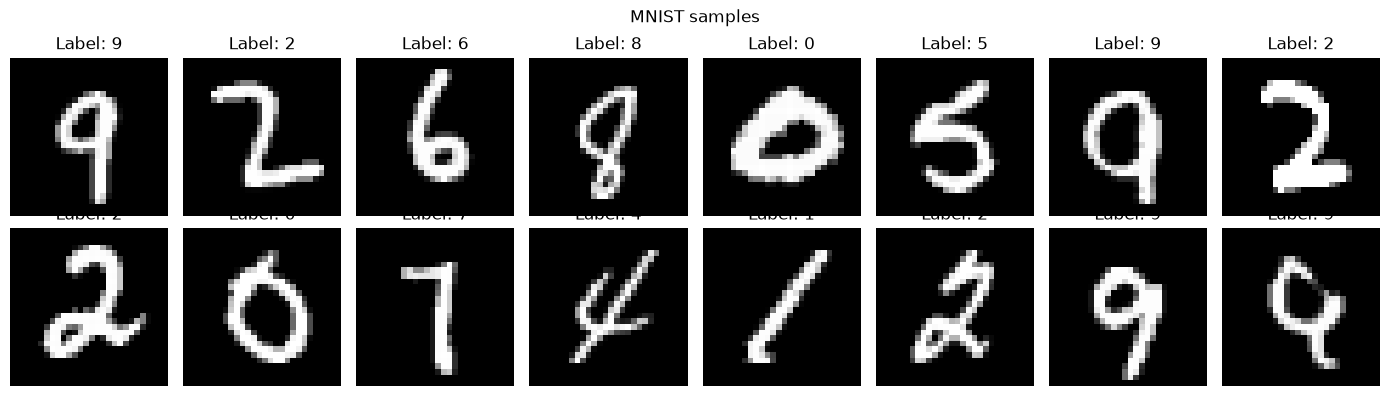

In [5]:
def show_images(imgs, lbls, n=16, title="MNIST samples"):
    fig, axes = plt.subplots(2, n // 2, figsize=(14, 4))
    for i, ax in enumerate(axes.flat):
        img = imgs[i].squeeze() * 0.3081 + 0.1307   # undo normalization for display
        ax.imshow(img, cmap="gray")
        ax.set_title(f"Label: {lbls[i].item()}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_images(images, labels)

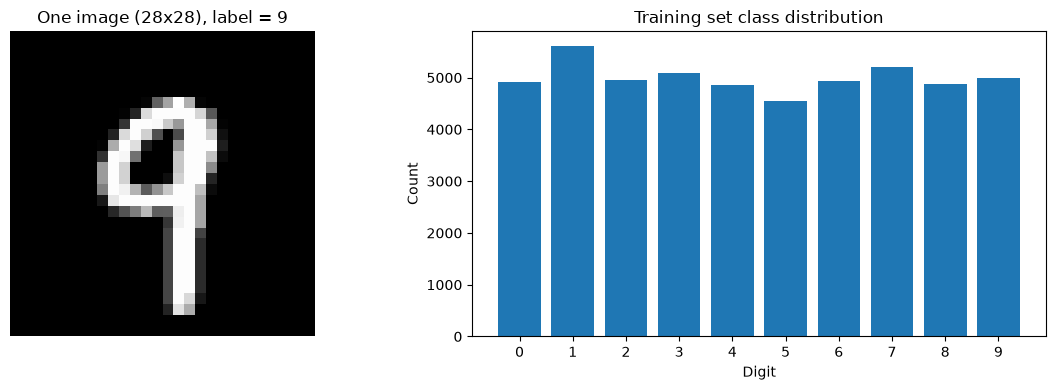

In [6]:
# Single image in detail + class distribution of the training set
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow((images[0].squeeze() * 0.3081 + 0.1307).clamp(0, 1), cmap="gray")
ax[0].set_title(f"One image (28x28), label = {labels[0].item()}")
ax[0].axis("off")

train_targets = full_train.targets[train_set.indices]
counts = torch.bincount(train_targets, minlength=10)
ax[1].bar(range(10), counts.numpy())
ax[1].set_xticks(range(10))
ax[1].set_xlabel("Digit"); ax[1].set_ylabel("Count")
ax[1].set_title("Training set class distribution")
plt.tight_layout(); plt.show()

## Task 4: Creating A Simple Network
One hidden layer: `Linear(784 → hidden)` → **ReLU** → `Linear(hidden → 10)`.
`nn.Linear` expects a 2D input (N × I), so the (N × C × H × W) batch is reshaped with
`torch.flatten`: **(32 × 1 × 28 × 28) → (32 × 784)**.

In [ ]:
class SimpleNet(nn.Module):
    def __init__(self, num_inputs=784, num_hidden=128, num_outputs=10):
        super().__init__()
        self.fc1  = nn.Linear(num_inputs, num_hidden)    # input  -> hidden
        self.relu = nn.ReLU()                            # activation function
        self.fc2  = nn.Linear(num_hidden, num_outputs)   # hidden -> output

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)   # (N,1,28,28) -> (N,784)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)                     # logits for 10 classes
        return x

net = SimpleNet().to(device)
print(net)
print("Trainable parameters:", sum(p.numel() for p in net.parameters() if p.requires_grad))

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 101770


In [8]:
# Verify the code against the requirement
x = images.to(device)
print("Input batch shape  :", tuple(x.shape))                           # (32, 1, 28, 28)
print("After flatten      :", tuple(torch.flatten(x, start_dim=1).shape)) # (32, 784)
print("Network output     :", tuple(net(x).shape))                       # (32, 10)

assert torch.flatten(x, start_dim=1).shape == (32, 784)
assert net(x).shape == (32, 10)
print("Requirement verified: (32 x 1 x 28 x 28) -> (32 x 784) -> (32 x 10)")

Input batch shape  : (32, 1, 28, 28)
After flatten      : (32, 784)
Network output     : (32, 10)
Requirement verified: (32 x 1 x 28 x 28) -> (32 x 784) -> (32 x 10)


## Task 5: Training Function
- Inputs: the network and the training dataloader, plus optional parameters
  (`epochs`, `lr`, `momentum`, `print_every`, `verbose`).
- Loss: `nn.CrossEntropyLoss` (softmax + negative log-likelihood).
- Optimizer: SGD with learning rate and momentum.
- Prints epoch, batch number, current loss and accuracy; returns all mini-batch losses
  plus per-epoch loss and accuracy.

In [ ]:
def train(net, dataloader, epochs=5, lr=0.01, momentum=0.9,
          print_every=200, verbose=True):
    net.to(device)
    net.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)

    batch_losses = []                  # loss of every mini-batch
    epoch_losses, epoch_accs = [], []  # averages per epoch

    for epoch in range(1, epochs + 1):
        running_loss, running_correct, running_total = 0.0, 0, 0
        epoch_loss_sum, epoch_correct, epoch_total = 0.0, 0, 0

        for batch_idx, (inputs, targets) in enumerate(dataloader, start=1):
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()              # reset gradients
            outputs = net(inputs)              # forward pass
            loss = criterion(outputs, targets) # compute loss
            loss.backward()                    # backpropagation
            optimizer.step()                   # update weights

            batch_losses.append(loss.item())
            preds = outputs.argmax(dim=1)
            correct = (preds == targets).sum().item()

            running_loss += loss.item(); running_correct += correct
            running_total += targets.size(0)
            epoch_loss_sum += loss.item() * targets.size(0)
            epoch_correct += correct; epoch_total += targets.size(0)

            if verbose and batch_idx % print_every == 0:
                print(f"Epoch [{epoch}/{epochs}]  Batch [{batch_idx}/{len(dataloader)}]  "
                      f"Loss: {running_loss / print_every:.4f}  "
                      f"Accuracy: {100 * running_correct / running_total:.2f}%")
                running_loss, running_correct, running_total = 0.0, 0, 0

        epoch_losses.append(epoch_loss_sum / epoch_total)
        epoch_accs.append(100 * epoch_correct / epoch_total)
        if verbose:
            print(f"==> Epoch {epoch} finished | Avg loss: {epoch_losses[-1]:.4f} | "
                  f"Accuracy: {epoch_accs[-1]:.2f}%\n")

    return batch_losses, epoch_losses, epoch_accs

In [10]:
def evaluate(net, dataloader):
    """Returns (average loss, accuracy %) on a dataloader without updating weights."""
    net.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = net(inputs)
            total_loss += criterion(outputs, targets).item()
            correct += (outputs.argmax(1) == targets).sum().item()
            total += targets.size(0)
    return total_loss / total, 100 * correct / total

def train_with_validation(model, train_dl, validation_dl, epochs, lr, momentum, verbose=False):
    """Train while recording comparable train/validation curves per epoch."""
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        loss_sum = correct = total = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            output = model(x)
            loss = criterion(output, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.size(0)
            correct += (output.argmax(1) == y).sum().item()
            total += y.size(0)
        vloss, vacc = evaluate(model, validation_dl)
        history["train_loss"].append(loss_sum / total)
        history["train_acc"].append(100 * correct / total)
        history["val_loss"].append(vloss)
        history["val_acc"].append(vacc)
        if verbose:
            print(f"Epoch {epoch+1}/{epochs}: train acc {history['train_acc'][-1]:.2f}% | val acc {vacc:.2f}%")
    return history, time.perf_counter() - start


## Task 6: Training Network
### 6.1 Instantiate a new network and train it

In [11]:
EPOCHS, LR, MOMENTUM = 5, 0.01, 0.9

set_seed(42)
net = SimpleNet(num_hidden=128).to(device)
start = time.time()
batch_losses, epoch_losses, epoch_accs = train(net, train_loader,
                                               epochs=EPOCHS, lr=LR, momentum=MOMENTUM,
                                               print_every=200)
print(f"Training time: {time.time() - start:.1f} s")

val_loss, val_acc = evaluate(net, val_loader)
print(f"Validation  -> loss: {val_loss:.4f} | accuracy: {val_acc:.2f}%")

Epoch [1/5]  Batch [200/1563]  Loss: 0.5556  Accuracy: 83.05%
Epoch [1/5]  Batch [400/1563]  Loss: 0.2854  Accuracy: 91.14%
Epoch [1/5]  Batch [600/1563]  Loss: 0.2348  Accuracy: 93.00%
Epoch [1/5]  Batch [800/1563]  Loss: 0.1849  Accuracy: 94.80%
Epoch [1/5]  Batch [1000/1563]  Loss: 0.1679  Accuracy: 95.03%
Epoch [1/5]  Batch [1200/1563]  Loss: 0.1661  Accuracy: 94.92%
Epoch [1/5]  Batch [1400/1563]  Loss: 0.1517  Accuracy: 95.33%
==> Epoch 1 finished | Avg loss: 0.2374 | Accuracy: 92.83%

Epoch [2/5]  Batch [200/1563]  Loss: 0.0970  Accuracy: 96.97%
Epoch [2/5]  Batch [400/1563]  Loss: 0.1017  Accuracy: 96.81%
Epoch [2/5]  Batch [600/1563]  Loss: 0.0942  Accuracy: 97.44%
Epoch [2/5]  Batch [800/1563]  Loss: 0.1039  Accuracy: 96.92%
Epoch [2/5]  Batch [1000/1563]  Loss: 0.0937  Accuracy: 97.09%
Epoch [2/5]  Batch [1200/1563]  Loss: 0.1068  Accuracy: 96.89%
Epoch [2/5]  Batch [1400/1563]  Loss: 0.0876  Accuracy: 97.41%
==> Epoch 2 finished | Avg loss: 0.0987 | Accuracy: 97.07%

Epoch 

### 6.2 Graphs of the overall training process

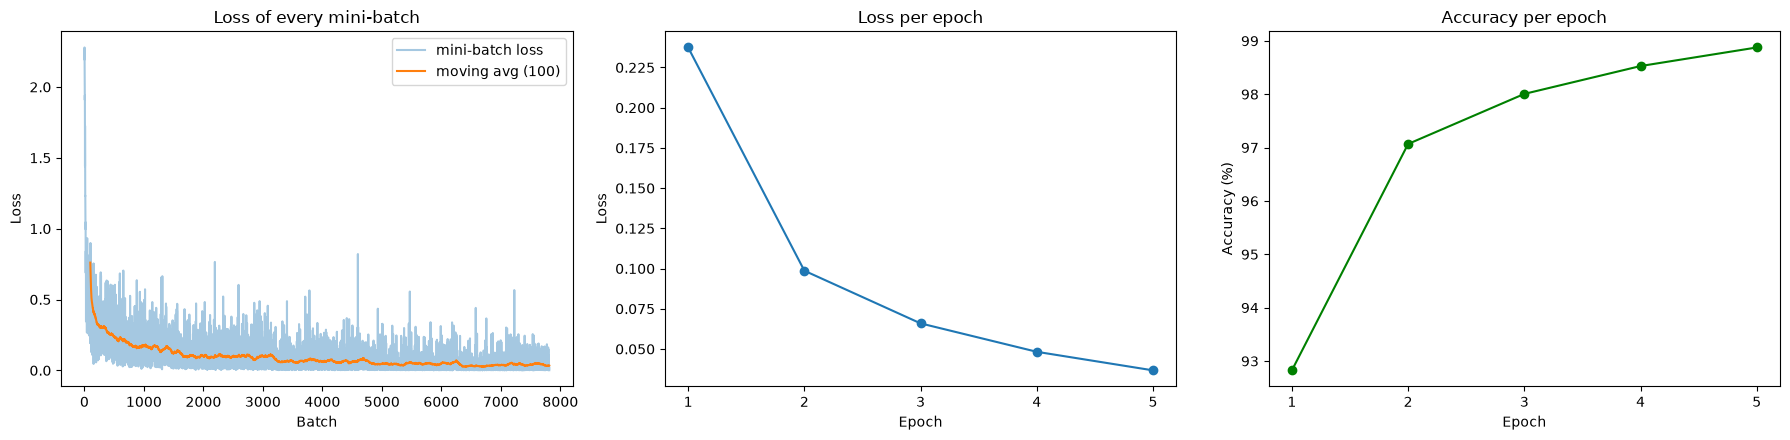

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

ax[0].plot(batch_losses, alpha=0.4, label="mini-batch loss")
w = 100
smooth = np.convolve(batch_losses, np.ones(w) / w, mode="valid")
ax[0].plot(range(w - 1, len(batch_losses)), smooth, label=f"moving avg ({w})")
ax[0].set_title("Loss of every mini-batch"); ax[0].set_xlabel("Batch"); ax[0].set_ylabel("Loss")
ax[0].legend()

ep = range(1, EPOCHS + 1)
ax[1].plot(ep, epoch_losses, "o-"); ax[1].set_title("Loss per epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].set_xticks(list(ep))

ax[2].plot(ep, epoch_accs, "o-", color="green"); ax[2].set_title("Accuracy per epoch")
ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("Accuracy (%)"); ax[2].set_xticks(list(ep))

plt.tight_layout(); plt.show()

## Task 7: Testing Network
### 7.1 Test on a few test images

True labels     : [6, 4, 0, 1, 4, 1, 3, 9, 2, 7]
Predicted labels: [6, 4, 0, 1, 4, 1, 3, 9, 2, 7]
Validation loss    : 0.0999
Validation accuracy: 97.05%


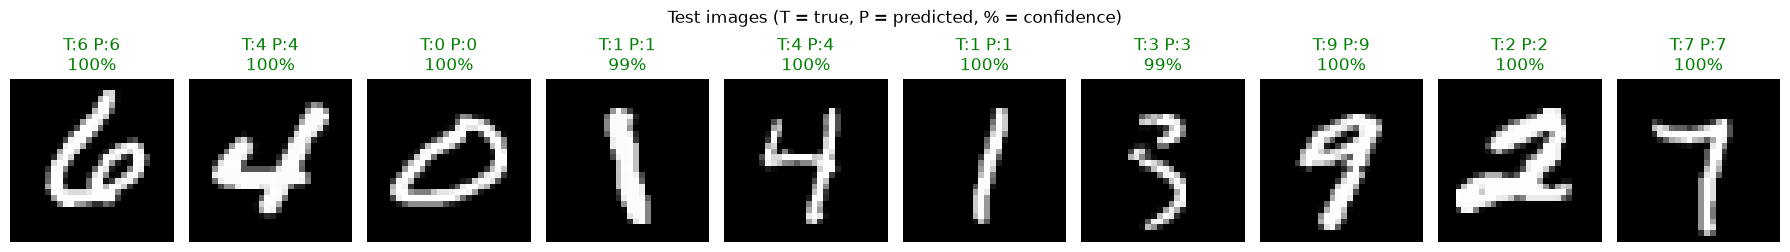

In [25]:
net.eval()
test_images, test_labels = next(iter(DataLoader(test_set, batch_size=10, shuffle=True)))
with torch.no_grad():
    outputs = net(test_images.to(device))
    probs = torch.softmax(outputs, dim=1)
    preds = probs.argmax(dim=1).cpu()

print("True labels     :", test_labels.tolist())
print("Predicted labels:", preds.tolist())

val_loss, val_acc = evaluate(net, val_loader)
print(f"Validation loss    : {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.2f}%")


fig, axes = plt.subplots(1, 10, figsize=(18, 2.8))
for i, ax in enumerate(axes):
    ax.imshow(test_images[i].squeeze() * 0.3081 + 0.1307, cmap="gray")
    ok = preds[i] == test_labels[i]
    ax.set_title(f"T:{test_labels[i].item()} P:{preds[i].item()}\n{probs[i].max().item():.0%}",
                 color="green" if ok else "red")
    ax.axis("off")
plt.suptitle("Test images (T = true, P = predicted, % = confidence)")
plt.tight_layout(); plt.show()

## Task 8: Tuning the Parameters and Model Architecture
Each configuration is trained on the training set and compared on the **validation set**
(the test set is kept for the final check only). Fewer epochs are used per run to keep the
search fast; increase `TUNE_EPOCHS` if you have time/GPU.

### 8.1 Tuning learning rate and momentum

In [14]:
TUNE_EPOCHS = 3
learning_rates = [0.001, 0.01, 0.05, 0.1]
momentums      = [0.0, 0.5, 0.9]

lr_results = []
for lr in learning_rates:
    for m in momentums:
        set_seed(42)
        model = SimpleNet(num_hidden=128).to(device)
        start = time.perf_counter()
        _, tr_losses, tr_accs = train(model, train_loader, epochs=TUNE_EPOCHS,
                                      lr=lr, momentum=m, verbose=False)
        v_loss, v_acc = evaluate(model, val_loader)
        lr_results.append({"lr": lr, "momentum": m, "train_loss": tr_losses[-1],
                           "val_loss": v_loss, "val_acc": v_acc,
                           "seconds": time.perf_counter() - start})
        print(f"lr={lr:<6} momentum={m:<4} | train loss {tr_losses[-1]:.4f} | "
              f"val loss {v_loss:.4f} | val acc {v_acc:.2f}%")

lr=0.001  momentum=0.0  | train loss 0.4492 | val loss 0.4231 | val acc 88.75%
lr=0.001  momentum=0.5  | train loss 0.3533 | val loss 0.3431 | val acc 90.12%
lr=0.001  momentum=0.9  | train loss 0.2074 | val loss 0.2042 | val acc 94.13%
lr=0.01   momentum=0.0  | train loss 0.2066 | val loss 0.2043 | val acc 94.05%
lr=0.01   momentum=0.5  | train loss 0.1440 | val loss 0.1505 | val acc 95.69%
lr=0.01   momentum=0.9  | train loss 0.0659 | val loss 0.1004 | val acc 96.88%
lr=0.05   momentum=0.0  | train loss 0.0858 | val loss 0.1103 | val acc 96.70%
lr=0.05   momentum=0.5  | train loss 0.0667 | val loss 0.1015 | val acc 96.94%
lr=0.05   momentum=0.9  | train loss 0.2143 | val loss 0.3068 | val acc 93.88%
lr=0.1    momentum=0.0  | train loss 0.0660 | val loss 0.1006 | val acc 97.08%
lr=0.1    momentum=0.5  | train loss 0.0726 | val loss 0.1077 | val acc 96.81%
lr=0.1    momentum=0.9  | train loss 0.8942 | val loss 0.9047 | val acc 76.92%


,lr,momentum,train_loss,val_loss,val_acc,seconds
9,0.100000,0.000000,0.0660,0.1006,97.08,77.907948
7,0.050000,0.500000,0.0667,0.1015,96.94,77.500115
5,0.010000,0.900000,0.0659,0.1004,96.88,26.952135
10,0.100000,0.500000,0.0726,0.1077,96.81,78.787148
6,0.050000,0.000000,0.0858,0.1103,96.70,74.592727
4,0.010000,0.500000,0.1440,0.1505,95.69,26.951270
2,0.001000,0.900000,0.2074,0.2042,94.13,26.919363
3,0.010000,0.000000,0.2066,0.2043,94.05,26.397605
8,0.050000,0.900000,0.2143,0.3068,93.88,79.891993
1,0.001000,0.500000,0.3533,0.3431,90.12,29.332533


Best: lr = 0.1, momentum = 0.0 -> val loss 0.1006, val acc 97.08%


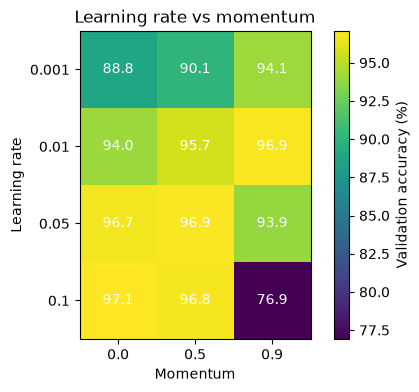

In [15]:
import pandas as pd
lr_df = pd.DataFrame(lr_results).sort_values("val_acc", ascending=False)
display(lr_df.style.format({"train_loss": "{:.4f}", "val_loss": "{:.4f}", "val_acc": "{:.2f}"})
        .highlight_max(subset=["val_acc"], color="lightgreen")
        .highlight_min(subset=["val_loss"], color="lightblue"))

best_lr_row = lr_df.iloc[0]
BEST_LR, BEST_MOMENTUM = float(best_lr_row["lr"]), float(best_lr_row["momentum"])
print(f"Best: lr = {BEST_LR}, momentum = {BEST_MOMENTUM} -> "
      f"val loss {best_lr_row['val_loss']:.4f}, val acc {best_lr_row['val_acc']:.2f}%")

# Heatmap of validation accuracy
pivot = lr_df.pivot(index="lr", columns="momentum", values="val_acc")
plt.figure(figsize=(6, 4))
plt.imshow(pivot.values, cmap="viridis")
plt.colorbar(label="Validation accuracy (%)")
plt.xticks(range(len(pivot.columns)), pivot.columns); plt.xlabel("Momentum")
plt.yticks(range(len(pivot.index)), pivot.index);     plt.ylabel("Learning rate")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        plt.text(j, i, f"{pivot.values[i, j]:.1f}", ha="center", va="center", color="w")
plt.title("Learning rate vs momentum"); plt.show()

### 8.2 Tuning the architecture (number of hidden layers and neurons)
`FlexibleNet` builds any number of hidden layers, each with its own number of neurons,
using ReLU after every hidden layer. The best learning rate and momentum from 8.1 are used.

In [16]:
class FlexibleNet(nn.Module):
    def __init__(self, hidden_sizes=(128,), num_inputs=784, num_outputs=10):
        super().__init__()
        layers, prev = [], num_inputs
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, num_outputs))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(torch.flatten(x, start_dim=1))

architectures = [
    (32,), (64,), (128,), (256,), (512,),          # 1 hidden layer, varying neurons
    (128, 64), (256, 128), (512, 256),             # 2 hidden layers
    (256, 128, 64), (512, 256, 128),               # 3 hidden layers
    (512, 256, 128, 64),                           # 4 hidden layers
]

arch_results = []
for hs in architectures:
    set_seed(42)
    model = FlexibleNet(hs).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    start = time.perf_counter()
    _, tr_losses, _ = train(model, train_loader, epochs=TUNE_EPOCHS,
                            lr=BEST_LR, momentum=BEST_MOMENTUM, verbose=False)
    v_loss, v_acc = evaluate(model, val_loader)
    arch_results.append({"hidden_layers": len(hs), "neurons": hs, "params": n_params,
                         "train_loss": tr_losses[-1], "val_loss": v_loss, "val_acc": v_acc,
                         "seconds": time.perf_counter() - start})
    print(f"{len(hs)} layer(s) {str(hs):<22} params {n_params:>7} | "
          f"val loss {v_loss:.4f} | val acc {v_acc:.2f}%")

1 layer(s) (32,)                  params   25450 | val loss 0.1519 | val acc 95.51%
1 layer(s) (64,)                  params   50890 | val loss 0.1323 | val acc 96.08%
1 layer(s) (128,)                 params  101770 | val loss 0.1006 | val acc 97.08%
1 layer(s) (256,)                 params  203530 | val loss 0.0827 | val acc 97.45%
1 layer(s) (512,)                 params  407050 | val loss 0.0766 | val acc 97.64%
2 layer(s) (128, 64)              params  109386 | val loss 0.1107 | val acc 96.79%
2 layer(s) (256, 128)             params  235146 | val loss 0.1162 | val acc 96.51%
2 layer(s) (512, 256)             params  535818 | val loss 0.0830 | val acc 97.41%
3 layer(s) (256, 128, 64)         params  242762 | val loss 0.1112 | val acc 96.42%
3 layer(s) (512, 256, 128)        params  567434 | val loss 0.1079 | val acc 96.78%
4 layer(s) (512, 256, 128, 64)    params  575050 | val loss 0.0868 | val acc 97.59%


,hidden_layers,neurons,params,train_loss,val_loss,val_acc,seconds
4,1,"(512,)",407050,0.0526,0.0766,97.64,33.244384
10,4,"(512, 256, 128, 64)",575050,0.0681,0.0868,97.59,45.632985
3,1,"(256,)",203530,0.0571,0.0827,97.45,29.675124
7,2,"(512, 256)",535818,0.0543,0.0830,97.41,41.462052
2,1,"(128,)",101770,0.0660,0.1006,97.08,28.543779
5,2,"(128, 64)",109386,0.0703,0.1107,96.79,42.700898
9,3,"(512, 256, 128)",567434,0.0609,0.1079,96.78,51.275330
6,2,"(256, 128)",235146,0.0615,0.1162,96.51,34.473909
8,3,"(256, 128, 64)",242762,0.0684,0.1112,96.42,40.224334
1,1,"(64,)",50890,0.0827,0.1323,96.08,54.469722


Best architecture (hidden sizes): (512,)


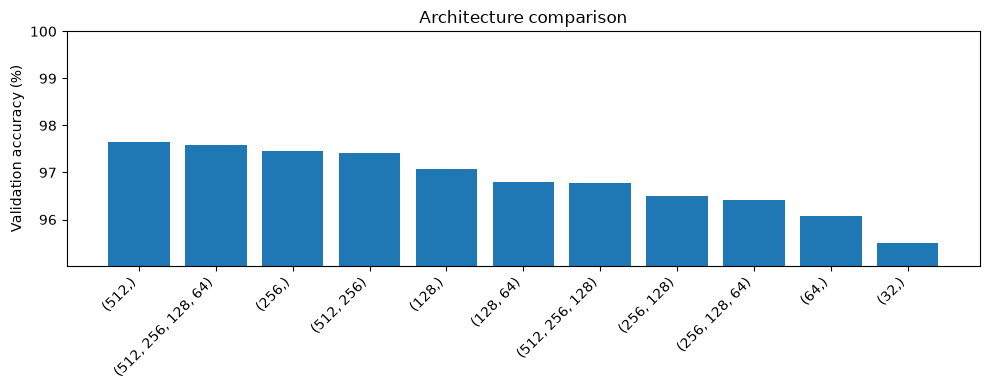

In [17]:
arch_df = pd.DataFrame(arch_results).sort_values("val_acc", ascending=False)
display(arch_df.style.format({"train_loss": "{:.4f}", "val_loss": "{:.4f}", "val_acc": "{:.2f}"})
        .highlight_max(subset=["val_acc"], color="lightgreen")
        .highlight_min(subset=["val_loss"], color="lightblue"))

BEST_ARCH = tuple(arch_df.iloc[0]["neurons"])
print("Best architecture (hidden sizes):", BEST_ARCH)

plt.figure(figsize=(10, 4))
plt.bar(arch_df["neurons"].astype(str), arch_df["val_acc"])
plt.ylim(arch_df["val_acc"].min() - 0.5, 100)
plt.xticks(rotation=45, ha="right"); plt.ylabel("Validation accuracy (%)")
plt.title("Architecture comparison"); plt.tight_layout(); plt.show()

### 8.3 Controlled architecture experiments

To distinguish **width** from **depth**, compare single-hidden-layer networks of different widths, then compare networks with the same width (128 units) but different depths. Parameter count still grows with depth, so this does **not** hold total capacity constant. All configurations use the same number of epochs and the selected learning rate/momentum.

,neurons,params,val_acc,seconds
0,"(32,)",25450,95.51,77.329913
1,"(64,)",50890,96.08,54.469722
2,"(128,)",101770,97.08,28.543779
3,"(256,)",203530,97.45,29.675124
4,"(512,)",407050,97.64,33.244384


,hidden_layers,neurons,params,train_loss,val_loss,val_acc,seconds
0,1,"(128,)",101770,0.065962,0.100576,97.08,28.543779
1,2,"(128, 128)",118282,0.069234,0.105153,96.96,39.109499
2,3,"(128, 128, 128)",134794,0.074396,0.105664,97.15,31.104699
3,4,"(128, 128, 128, 128)",151306,0.083594,0.114609,96.57,30.829136


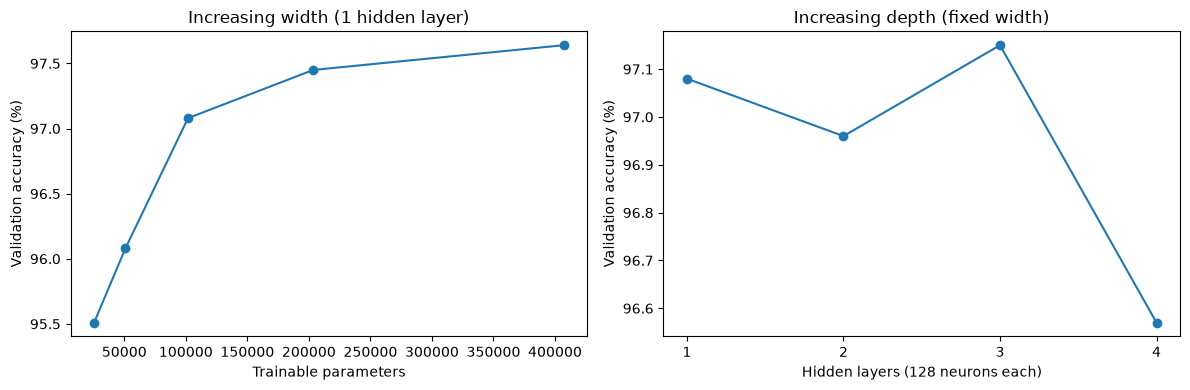

In [18]:
# Width-only results from the architecture sweep above
width_df = arch_df[arch_df["hidden_layers"] == 1].sort_values("params").copy()
display(width_df[["neurons", "params", "val_acc", "seconds"]])

# Fixed-width depth comparison; reuse (128,) result from original sweep
fixed_width_archs = [(128, 128), (128, 128, 128), (128, 128, 128, 128)]
depth_rows = [dict(r) for _, r in arch_df.iterrows() if r["neurons"] == (128,)]
for hs in fixed_width_archs:
    set_seed(42)
    model = FlexibleNet(hs).to(device)
    start = time.perf_counter()
    _, losses, _ = train(model, train_loader, epochs=TUNE_EPOCHS,
                         lr=BEST_LR, momentum=BEST_MOMENTUM, verbose=False)
    vloss, vacc = evaluate(model, val_loader)
    depth_rows.append({"hidden_layers": len(hs), "neurons": hs,
                       "params": sum(p.numel() for p in model.parameters()),
                       "train_loss": losses[-1], "val_loss": vloss,
                       "val_acc": vacc, "seconds": time.perf_counter()-start})
depth_df = pd.DataFrame(depth_rows).sort_values("hidden_layers")
display(depth_df)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(width_df["params"], width_df["val_acc"], "o-")
ax[0].set(xlabel="Trainable parameters", ylabel="Validation accuracy (%)", title="Increasing width (1 hidden layer)")
ax[1].plot(depth_df["hidden_layers"], depth_df["val_acc"], "o-")
ax[1].set(xlabel="Hidden layers (128 neurons each)", ylabel="Validation accuracy (%)", title="Increasing depth (fixed width)")
ax[1].set_xticks(depth_df["hidden_layers"])
plt.tight_layout(); plt.show()

### 8.3 Final model with the best parameters and architecture

Epoch 1/10: train acc 92.83% | val acc 96.22%
Epoch 2/10: train acc 97.06% | val acc 96.86%
Epoch 3/10: train acc 97.97% | val acc 96.99%
Epoch 4/10: train acc 98.43% | val acc 97.35%
Epoch 5/10: train acc 98.82% | val acc 97.48%
Epoch 6/10: train acc 99.20% | val acc 97.57%
Epoch 7/10: train acc 99.44% | val acc 97.37%
Epoch 8/10: train acc 99.62% | val acc 97.60%
Epoch 9/10: train acc 99.77% | val acc 97.60%
Epoch 10/10: train acc 99.87% | val acc 97.70%
Epoch 1/10: train acc 93.68% | val acc 95.39%
Epoch 2/10: train acc 97.46% | val acc 96.88%
Epoch 3/10: train acc 98.43% | val acc 96.95%
Epoch 4/10: train acc 98.97% | val acc 97.52%
Epoch 5/10: train acc 99.38% | val acc 97.61%
Epoch 6/10: train acc 99.67% | val acc 97.83%
Epoch 7/10: train acc 99.82% | val acc 97.83%
Epoch 8/10: train acc 99.93% | val acc 97.85%
Epoch 9/10: train acc 99.97% | val acc 97.91%
Epoch 10/10: train acc 99.99% | val acc 97.86%


,model,architecture,lr,momentum,params,seconds,val_acc,test_loss,test_acc
0,Baseline,"(128,)",0.01,0.9,101770,102.962284,97.70,0.079906,98.03
1,Tuned,"(512,)",0.10,0.0,407050,103.727731,97.86,0.059720,98.36


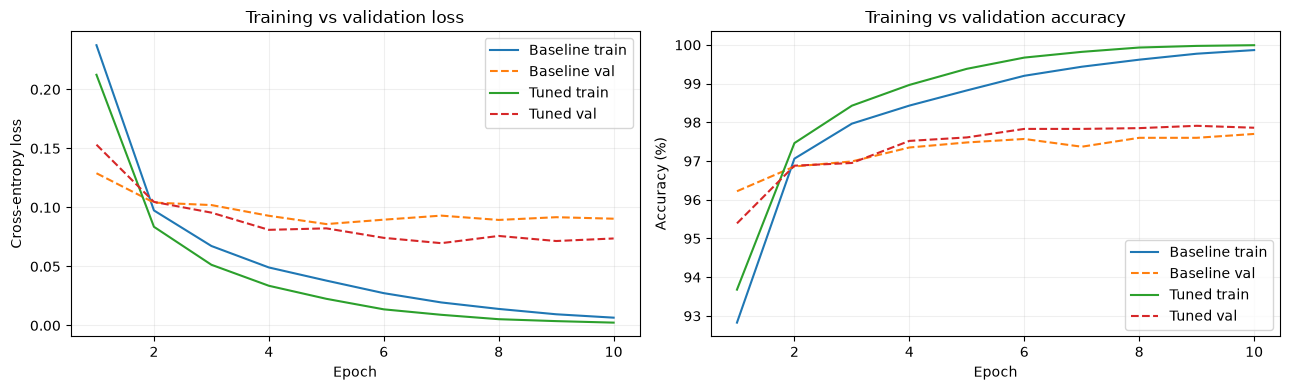

In [19]:
# Fair comparison: both baseline and selected model train for the SAME number of epochs.
FINAL_EPOCHS = 10
set_seed(42)
baseline_final = SimpleNet(num_hidden=128).to(device)
baseline_history, baseline_seconds = train_with_validation(
    baseline_final, train_loader, val_loader, FINAL_EPOCHS, LR, MOMENTUM, verbose=True)

set_seed(42)
best_net = FlexibleNet(BEST_ARCH).to(device)
best_history, best_seconds = train_with_validation(
    best_net, train_loader, val_loader, FINAL_EPOCHS,
    BEST_LR, BEST_MOMENTUM, verbose=True)

# Only now, after selection, evaluate once on the held-out test set.
baseline_test_loss, baseline_test_acc = evaluate(baseline_final, test_loader)
best_test_loss, best_test_acc = evaluate(best_net, test_loader)
comparison = pd.DataFrame([
    {"model": "Baseline", "architecture": "(128,)", "lr": LR, "momentum": MOMENTUM,
     "params": sum(p.numel() for p in baseline_final.parameters()),
     "seconds": baseline_seconds, "val_acc": baseline_history["val_acc"][-1],
     "test_loss": baseline_test_loss, "test_acc": baseline_test_acc},
    {"model": "Tuned", "architecture": str(BEST_ARCH), "lr": BEST_LR, "momentum": BEST_MOMENTUM,
     "params": sum(p.numel() for p in best_net.parameters()),
     "seconds": best_seconds, "val_acc": best_history["val_acc"][-1],
     "test_loss": best_test_loss, "test_acc": best_test_acc}
])
display(comparison)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for label, hist in [("Baseline", baseline_history), ("Tuned", best_history)]:
    for split, linestyle in [("train", "-"), ("val", "--")]:
        ax[0].plot(range(1, FINAL_EPOCHS+1), hist[f"{split}_loss"], linestyle,
                   label=f"{label} {split}")
        ax[1].plot(range(1, FINAL_EPOCHS+1), hist[f"{split}_acc"], linestyle,
                   label=f"{label} {split}")
ax[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Training vs validation loss")
ax[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Training vs validation accuracy")
for a in ax: a.legend(); a.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## Task 9: Save Your Source Code
Save the trained model, export this notebook as a `.py` script, and push both to GitHub.

In [20]:
# Save trained model weights
torch.save(best_net.state_dict(), "best_mnist_model.pth")
print("Model saved to best_mnist_model.pth")

# Reload to confirm it was saved correctly
reloaded = FlexibleNet(BEST_ARCH).to(device)
reloaded.load_state_dict(torch.load("best_mnist_model.pth", map_location=device))
print("Reloaded model test accuracy: %.2f%%" % evaluate(reloaded, test_loader)[1])

Model saved to best_mnist_model.pth
Reloaded model test accuracy: 98.36%
